# 1

### Nota: 10

En este ejercicio queremos que realices un análisis exploratorio de datos semanales de ventas, identificando valores nulos y outliers, calculando correlaciones entre variables, y visualizando la relación entre el precio y las unidades vendidas mediante un gráfico de dispersión, utilizando Pandas.

semana               0
unidades_vendidas    0
precio               0
publicidad_1         0
oferta_1             8
dtype: int64


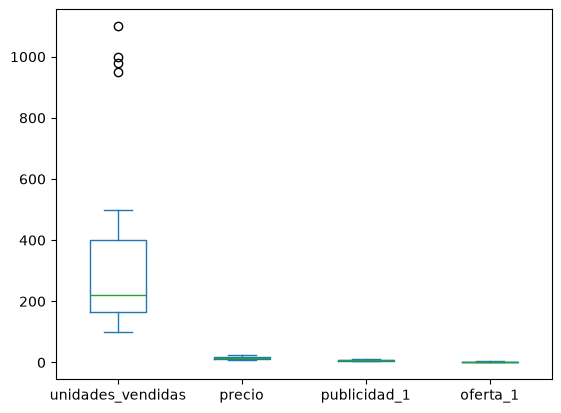

                   unidades_vendidas    precio  publicidad_1
unidades_vendidas           1.000000  0.695364      0.505473
precio                      0.695364  1.000000      0.722081
publicidad_1                0.505473  0.722081      1.000000


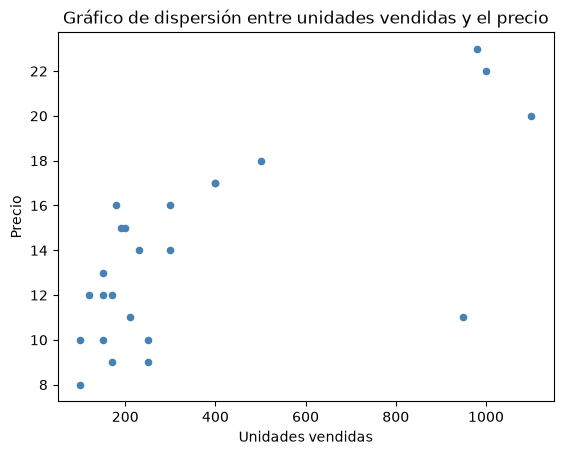

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

data = [
    {"semana": "2023-01-01", "unidades_vendidas": 100, "precio": 8, "publicidad_1": 5, "oferta_1": None},
    {"semana": "2023-01-08", "unidades_vendidas": 200, "precio": 15, "publicidad_1": 8, "oferta_1": 2},
    {"semana": "2023-01-15", "unidades_vendidas": 950, "precio": 11, "publicidad_1": 6, "oferta_1": 3},
    {"semana": "2023-01-22", "unidades_vendidas": 150, "precio": 10, "publicidad_1": 7, "oferta_1": 1},
    {"semana": "2023-01-29", "unidades_vendidas": 1100, "precio": 20, "publicidad_1": 9, "oferta_1": None},
    {"semana": "2023-02-05", "unidades_vendidas": 120, "precio": 12, "publicidad_1": 5, "oferta_1": 2},
    {"semana": "2023-02-12", "unidades_vendidas": 250, "precio": 9, "publicidad_1": 8, "oferta_1": 1},
    {"semana": "2023-02-19", "unidades_vendidas": 300, "precio": 14, "publicidad_1": 7, "oferta_1": None},
    {"semana": "2023-02-26", "unidades_vendidas": 400, "precio": 17, "publicidad_1": 9, "oferta_1": 3},
    {"semana": "2023-03-05", "unidades_vendidas": 150, "precio": 13, "publicidad_1": 5, "oferta_1": 2},
    {"semana": "2023-03-12", "unidades_vendidas": 100, "precio": 10, "publicidad_1": 6, "oferta_1": None},
    {"semana": "2023-03-19", "unidades_vendidas": 500, "precio": 18, "publicidad_1": 10, "oferta_1": 4},
    {"semana": "2023-03-26", "unidades_vendidas": 180, "precio": 16, "publicidad_1": 8, "oferta_1": 2},
    {"semana": "2023-04-02", "unidades_vendidas": 170, "precio": 12, "publicidad_1": 7, "oferta_1": 1},
    {"semana": "2023-04-09", "unidades_vendidas": 1000, "precio": 22, "publicidad_1": 9, "oferta_1": None},
    {"semana": "2023-04-16", "unidades_vendidas": 210, "precio": 11, "publicidad_1": 5, "oferta_1": 3},
    {"semana": "2023-04-23", "unidades_vendidas": 230, "precio": 14, "publicidad_1": 8, "oferta_1": 2},
    {"semana": "2023-04-30", "unidades_vendidas": 190, "precio": 15, "publicidad_1": 6, "oferta_1": 1},
    {"semana": "2023-05-07", "unidades_vendidas": 300, "precio": 16, "publicidad_1": 9, "oferta_1": 4},
    {"semana": "2023-05-14", "unidades_vendidas": 250, "precio": 10, "publicidad_1": 7, "oferta_1": None},
    {"semana": "2023-05-21", "unidades_vendidas": 400, "precio": 17, "publicidad_1": 10, "oferta_1": 3},
    {"semana": "2023-05-28", "unidades_vendidas": 980, "precio": 23, "publicidad_1": 9, "oferta_1": None},
    {"semana": "2023-06-04", "unidades_vendidas": 150, "precio": 12, "publicidad_1": 5, "oferta_1": 2},
    {"semana": "2023-06-11", "unidades_vendidas": 170, "precio": 9, "publicidad_1": 6, "oferta_1": None}
]

# Creamos el DataFrame y convertimos la columna de semana en datetime
df = pd.DataFrame(data)
df["semana"] = pd.to_datetime(df["semana"])

# Primero identificamos los valores nulos
print(df.isna().sum())

# Hay 8 valores nulos en oferta_1, primero aplicamos un forward fill, y luego un backward para el primer valor
df = df.assign(oferta_1 = lambda x: x.oferta_1.ffill())
df = df.assign(oferta_1 = lambda x: x.oferta_1.bfill())

# Vemos los outliers que existen en unidades_vendidas
df.plot.box()
plt.show()

# Calculamos el coeficiente de correlación de Pearson para el DataFrame
pearson_corr = df[["unidades_vendidas", "precio", "publicidad_1"]].corr(method = "pearson")
print(pearson_corr)

# Hacemos el gráfico entre las unidades vendidas y el precio para ver la correlación de 0.69
df.plot(x = "unidades_vendidas", y = "precio", kind = "scatter", c = "steelblue")
plt.title("Gráfico de dispersión entre unidades vendidas y el precio")
plt.xlabel("Unidades vendidas")
plt.ylabel("Precio")
plt.show()